# Fashion-MNIST Classification — Transfer Learning (MobileNetV2)

### 1. Data Preparation

In [1]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, tensorflow as tf
from tensorflow import keras
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train, y_train = x_train[:8000], y_train[:8000]   # subset = fast
names = ['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Boot']
IMG = 64

def prep(x, y):
    x = tf.image.grayscale_to_rgb(tf.expand_dims(x, -1))
    x = tf.image.resize(x, (IMG, IMG))
    x = keras.applications.mobilenet_v2.preprocess_input(tf.cast(x, tf.float32))
    return x, y

def ds(x, y): return tf.data.Dataset.from_tensor_slices((x, y)).map(prep).batch(256).prefetch(1)
train_ds, test_ds = ds(x_train, y_train), ds(x_test, y_test)
print("Ready:", x_train.shape, x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Ready: (8000, 28, 28) (10000, 28, 28)


### 2. Model Implementation (Transfer Learning)

In [2]:
base = keras.applications.MobileNetV2(input_shape=(IMG,IMG,3), include_top=False, weights='imagenet')
base.trainable = False
model = keras.Sequential([base, keras.layers.GlobalAveragePooling2D(),
                           keras.layers.Dropout(0.3), keras.layers.Dense(10, activation='softmax')])
model.compile('adam', 'sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

/tmp/ipykernel_4724/3497238414.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(input_shape=(IMG,IMG,3), include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 3. Model Training

In [3]:
history = model.fit(train_ds, validation_data=test_ds, epochs=3)

Epoch 1/3
32/32 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.4983 - loss: 1.5418 - val_accuracy: 0.7253 - val_loss: 0.8501
Epoch 2/3
32/32 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.7408 - loss: 0.7972 - val_accuracy: 0.7727 - val_loss: 0.6852
Epoch 3/3
32/32 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.7797 - loss: 0.6665 - val_accuracy: 0.7933 - val_loss: 0.6175


### 4. Performance Evaluation

In [4]:
y_pred = np.argmax(model.predict(test_ds), axis=1)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')
acc = model.evaluate(test_ds)[1]
print(f"Accuracy: {acc:.4f}  Precision: {p:.4f}  Recall: {r:.4f}  F1: {f1:.4f}")
print(classification_report(y_test, y_pred, target_names=names))

40/40 ━━━━━━━━━━━━━━━━━━━━ 29s 704ms/step
40/40 ━━━━━━━━━━━━━━━━━━━━ 27s 684ms/step - accuracy: 0.7933 - loss: 0.6175
Accuracy: 0.7933  Precision: 0.7968  Recall: 0.7933  F1: 0.7941
              precision    recall  f1-score   support

     T-shirt       0.80      0.68      0.74      1000
     Trouser       0.95      0.93      0.94      1000
    Pullover       0.73      0.77      0.75      1000
       Dress       0.73      0.74      0.74      1000
        Coat       0.71      0.65      0.68      1000
      Sandal       0.86      0.90      0.88      1000
       Shirt       0.52      0.58      0.55      1000
     Sneaker       0.85      0.88      0.86      1000
         Bag       0.92      0.89      0.90      1000
        Boot       0.90      0.91      0.90      1000

    accuracy                           0.79     10000
   macro avg       0.80      0.79      0.79     10000
weighted avg       0.80      0.79      0.79     10000



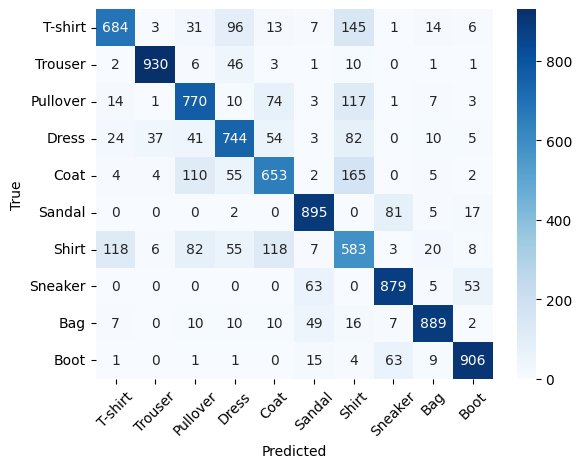

In [5]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=names, yticklabels=names, cmap='Blues')
plt.xticks(rotation=45); plt.xlabel('Predicted'); plt.ylabel('True'); plt.show()

### 5. Result Analysis

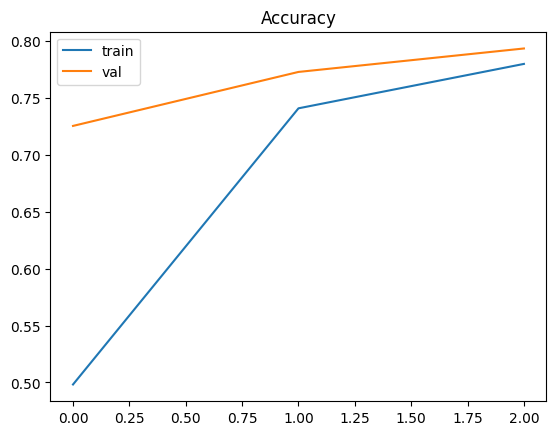

In [6]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend(); plt.title('Accuracy'); plt.show()

In [7]:
for n, a in sorted(zip(names, cm.diagonal()/cm.sum(1)), key=lambda t: t[1]):
    print(f"{n:10s}: {a:.3f}")

Shirt     : 0.583
Coat      : 0.653
T-shirt   : 0.684
Dress     : 0.744
Pullover  : 0.770
Sneaker   : 0.879
Bag       : 0.889
Sandal    : 0.895
Boot      : 0.906
Trouser   : 0.930
